# CineMatch — Exploratory Data Analysis

MovieLens `ml-latest-small`. Every figure quoted in README section 6 is produced here.
Statistics live in `scripts/eda.py` so they are reproducible from the CLI
(`python scripts/eda.py`) and cannot drift from the documentation.

Run `python scripts/download_data.py` first if `data/raw/` is empty.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / 'scripts'))
from eda import load_raw, summarise

plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': 0.3})

data = load_raw()
ratings, movies, tags, links = data['ratings'], data['movies'], data['tags'], data['links']
stats = summarise(data)
pd.Series(stats).to_frame('value')

,value
n_ratings,100836
n_users,610
n_catalogue,9742
n_rated_movies,9724
n_unrated_movies,18
n_tags,3683
density_pct,1.6968
rating_min,0.5
rating_max,5.0
rating_mean,3.502


## 1. Sparsity

The headline constraint. Density is computed against the **full catalogue**,
not just films that happen to carry a rating — the recommender can surface any
item, so that is the honest denominator.

In [2]:
n_users, n_cat = stats['n_users'], stats['n_catalogue']
print(f'user-item matrix: {n_users} x {n_cat} = {n_users * n_cat:,} cells')
print(f'observed ratings: {stats["n_ratings"]:,}')
print(f'density:          {stats["density_pct"]}%')
print(f'i.e. {100 - stats["density_pct"]:.2f}% of the matrix is unobserved')

user-item matrix: 610 x 9742 = 5,942,620 cells
observed ratings: 100,836
density:          1.6968%
i.e. 98.30% of the matrix is unobserved


## 2. Rating distribution

Determines the relevance threshold. We treat >= 4.0 as a positive signal;
this cell shows how much of the data that captures.

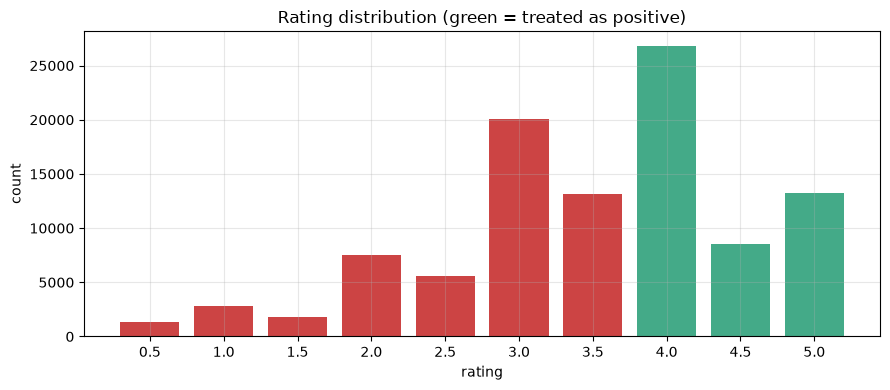

mean rating:  3.502
share >= 4.0: 48.2%  <- positive class
Half-star ratings appear only after 2003; the scale changed mid-dataset.


In [3]:
counts = ratings['rating'].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values,
       color=['#c44' if r < 4.0 else '#4a8' for r in counts.index])
ax.set_xlabel('rating'); ax.set_ylabel('count')
ax.set_title('Rating distribution (green = treated as positive)')
plt.tight_layout(); plt.show()

print(f'mean rating:  {stats["rating_mean"]}')
print(f'share >= 4.0: {stats["pct_positive"]}%  <- positive class')
print('Half-star ratings appear only after 2003; the scale changed mid-dataset.')

## 3. The long tail

This is the evidence behind the popularity-bias failure case (README F3) and the
reason MMR reranking earns its place.

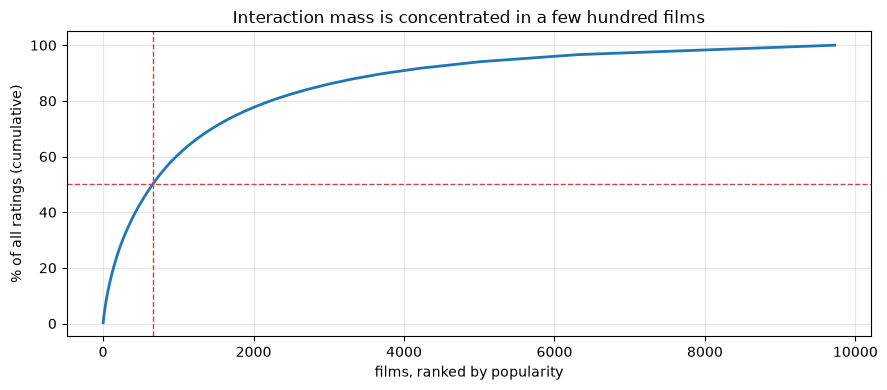

659 films (6.8% of catalogue) carry half of all ratings
the top 1% of films carry 15.7% of ratings
62.5% of films have fewer than 5 ratings
median ratings per film: 3


In [4]:
per_item = ratings.groupby('movieId').size().sort_values(ascending=False)
cum = np.cumsum(per_item.to_numpy()) / per_item.sum()

fig, ax = plt.subplots()
ax.plot(np.arange(1, len(cum) + 1), cum * 100, lw=2)
ax.axhline(50, ls='--', c='#c44', lw=1)
ax.axvline(stats['items_for_half_of_ratings'], ls='--', c='#c44', lw=1)
ax.set_xlabel('films, ranked by popularity')
ax.set_ylabel('% of all ratings (cumulative)')
ax.set_title('Interaction mass is concentrated in a few hundred films')
plt.tight_layout(); plt.show()

share = stats['items_for_half_of_ratings'] / stats['n_catalogue'] * 100
print(f'{stats["items_for_half_of_ratings"]} films ({share:.1f}% of catalogue) carry half of all ratings')
print(f'the top 1% of films carry {stats["top_1pct_share"]}% of ratings')
print(f'{stats["pct_items_under_5_ratings"]}% of films have fewer than 5 ratings')
print(f'median ratings per film: {stats["ratings_per_item_median"]}')

## 4. Users are pre-filtered — this constrains the evaluation

**Important caveat.** GroupLens only includes users with at least 20 ratings.
There are no genuinely cold users in this dataset, so cold-start quality cannot be
measured directly; it has to be *simulated* by truncating a warm user's history.
README section 10 is corrected to say so.

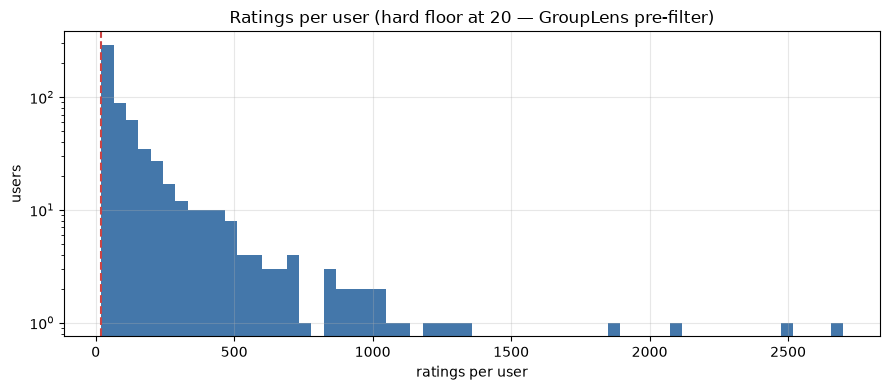

count     610.0
mean      165.3
std       269.5
min        20.0
25%        35.0
50%        70.5
75%       168.0
max      2698.0


In [5]:
per_user = ratings.groupby('userId').size()
fig, ax = plt.subplots()
ax.hist(per_user, bins=60, color='#47a')
ax.axvline(per_user.min(), ls='--', c='#c44', lw=1.5)
ax.set_xlabel('ratings per user'); ax.set_ylabel('users'); ax.set_yscale('log')
ax.set_title(f'Ratings per user (hard floor at {per_user.min()} — GroupLens pre-filter)')
plt.tight_layout(); plt.show()

print(per_user.describe().round(1).to_string())

## 5. Item cold start is real

A handful of catalogue films carry no ratings at all. Collaborative filtering can
never reach them; only the content model can.

In [6]:
rated = set(ratings['movieId'])
unrated = movies[~movies['movieId'].isin(rated)]
print(f'{len(unrated)} of {len(movies)} films have zero ratings')
unrated[['movieId', 'title', 'genres']].head(20)

18 of 9742 films have zero ratings


,movieId,title,genres
816,1076,"Innocents, The (1961)",Drama|Horror|Thriller
2211,2939,Niagara (1953),Drama|Thriller
2499,3338,For All Mankind (1989),Documentary
2587,3456,"Color of Paradise, The (Rang-e khoda) (1999)",Drama
3118,4194,I Know Where I'm Going! (1945),Drama|Romance|War
4037,5721,"Chosen, The (1981)",Drama
4506,6668,"Road Home, The (Wo de fu qin mu qin) (1999)",Drama|Romance
4598,6849,Scrooge (1970),Drama|Fantasy|Musical
4704,7020,Proof (1991),Comedy|Drama|Romance
5020,7792,"Parallax View, The (1974)",Thriller


## 6. Content signal available

What the embedding model has to work with: genres for every film, plus
user-generated tags for a minority of them.

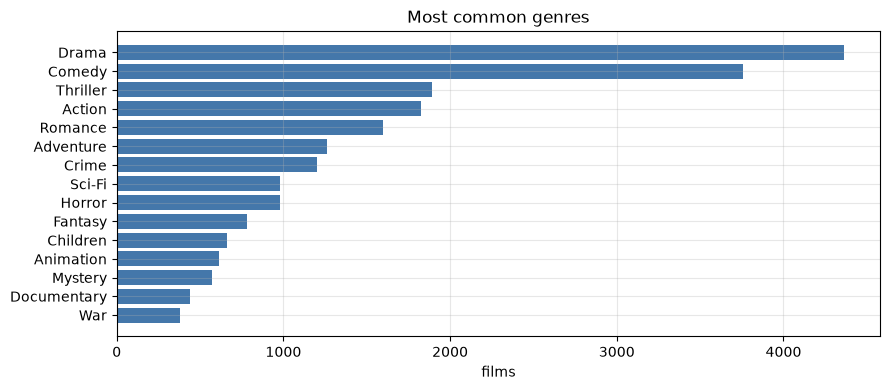

films with >= 1 tag: 1572 (16.1% of catalogue)
unique tag strings:  1589
films with no genres listed: 34
TMDB ids present: 9734 / 9742 (poster coverage ceiling)


In [7]:
exploded = movies['genres'].str.split('|').explode()
top = exploded.value_counts().head(15)
fig, ax = plt.subplots()
ax.barh(top.index[::-1], top.values[::-1], color='#47a')
ax.set_xlabel('films'); ax.set_title('Most common genres')
plt.tight_layout(); plt.show()

tagged = tags['movieId'].nunique()
print(f'films with >= 1 tag: {tagged} ({tagged / len(movies) * 100:.1f}% of catalogue)')
print(f'unique tag strings:  {tags["tag"].nunique()}')
print(f'films with no genres listed: {(movies["genres"] == "(no genres listed)").sum()}')
print(f'TMDB ids present: {links["tmdbId"].notna().sum()} / {len(links)} (poster coverage ceiling)')

## 7. Temporal span — justifies the split protocol

Ratings run over 22 years. A random train/test split would let the model see a
user's future when predicting their past, so the evaluation uses a per-user
temporal split instead (README section 10).

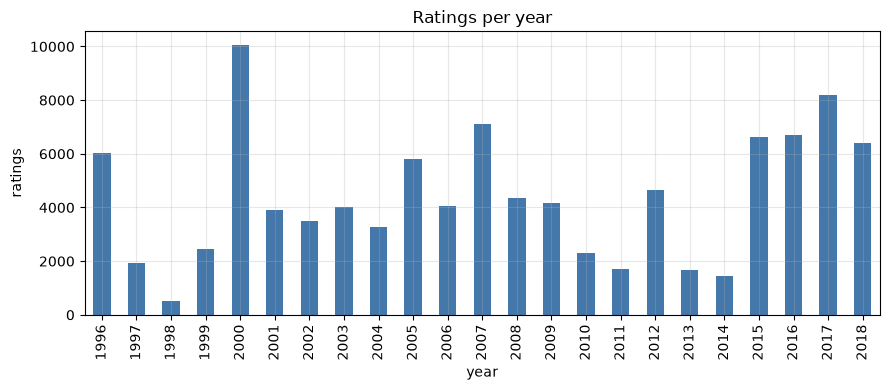

span: 1996-03-29 to 2018-09-24
Catalogue is frozen at 2018 — the staleness limitation (README F5) is a
data boundary, not a model defect.


In [8]:
ts = pd.to_datetime(ratings['timestamp'], unit='s')
fig, ax = plt.subplots()
ts.dt.year.value_counts().sort_index().plot(kind='bar', ax=ax, color='#47a')
ax.set_xlabel('year'); ax.set_ylabel('ratings'); ax.set_title('Ratings per year')
plt.tight_layout(); plt.show()

print(f'span: {stats["first_rating"]} to {stats["last_rating"]}')
print('Catalogue is frozen at 2018 — the staleness limitation (README F5) is a')
print('data boundary, not a model defect.')

## Summary — what this means for the design

| Observation | Consequence for the system |
|---|---|
| Density 1.70% | Pure collaborative filtering will be fragile; a content signal is required |
| 62.5% of films have < 5 ratings | Item-kNN neighbourhoods are unreliable in the tail |
| 659 films hold half the ratings | Popularity bias is structural — MMR reranking is justified |
| 18 films have zero ratings | Item cold start is unreachable without content embeddings |
| Every user has >= 20 ratings | Cold start must be *simulated*; it cannot be measured directly |
| 48.2% of ratings are >= 4.0 | The positive class is well balanced at that threshold |
| 22-year span | Temporal split is mandatory to avoid leakage |